# Gaussian Mixture

A Gaussian mixture models a density with elliptical components. Soft posterior responsibilities become hard labels for the cluster comparison.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Fit the grouping

The generator supplies reference labels for scoring. The estimator sees only the coordinates.

In [2]:
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from gallery.unsupervised import cluster_data, cluster_report

## Point cloud

In [3]:
X, reference = cluster_data("ellipses")
model = GaussianMixture(n_components=3, covariance_type="full", n_init=5, random_state=17)
labels = model.fit_predict(X)

## Group quality

External scores include every observation. Internal scores are calculated on assigned points.

Clusters: 3 | Assigned: 100.0% | Noise points: 0
Adjusted Rand index (all): 1.000
Adjusted mutual information (all): 1.000
Silhouette (assigned): 0.679
Davies–Bouldin (assigned): 0.452
Calinski–Harabasz (assigned): 2374.6
BIC: 2991.3 | AIC: 2919.4


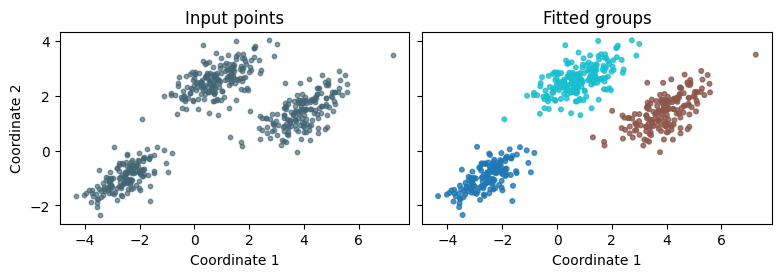

In [4]:
cluster_report(X, reference, labels)
print(f"BIC: {model.bic(X):.1f} | AIC: {model.aic(X):.1f}")
plt.show()

## Reading the result

The adjusted Rand index can be read without matching label numbers. Inspect the boundary points to see which observations account for disagreement.

## References

[scikit-learn, GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html)

[scikit-learn, make_blobs](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html)

[scikit-learn, clustering algorithms and evaluation](https://scikit-learn.org/stable/modules/clustering.html)

[Dataset generators and evaluation](../../../gallery/unsupervised.py)